In [1]:
!pip install torch torchvision pycocotools


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 427.8/427.8 kB 16.6 MB/s eta 0:00:00


In [2]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="NaDZYDZlRKZadUk1eNRs")
project = rf.workspace("non-bmqgg").project("saveaugmented")
version = project.version(2)
dataset = version.download("coco")
                

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.9 MB/s eta 0:00:00
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to SAVEaugmented-2 in coco:: 100%|██████████| 2077/2077 [00:00<00:00, 6542.49it/s]


In [2]:
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor
from torchvision.datasets import CocoDetection
import torchvision.models.detection as detection
import torchvision.ops as ops
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_fscore_support,
                             average_precision_score,
                             classification_report,
                             confusion_matrix)
from sklearn.preprocessing import LabelBinarizer
import seaborn as sns
from pycocotools.coco import COCO
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Detected Classes:
ID: 0, Name: trf78wey89
ID: 1, Name: ak
ID: 2, Name: bcc
ID: 3, Name: sk
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Number of training images: 1806
Number of validation images: 175
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Epoch 1/500 running...
Average loss for this epoch: 3.7852696870502673
Epoch 1/500 completed
Epoch 2/500 running...
Average loss for this epoch: 2.344014853761907
Epoch 2/500 completed
Epoch 3/500 running...
Average loss for this epoch: 1.9943526857777645
Epoch 3/500 completed
Epoch 4/500 running...
Average loss for this epoch: 1.7922546758986355
Epoch 4/500 completed
Epoch 5/500 running...
Average loss for this epoch: 1.6670

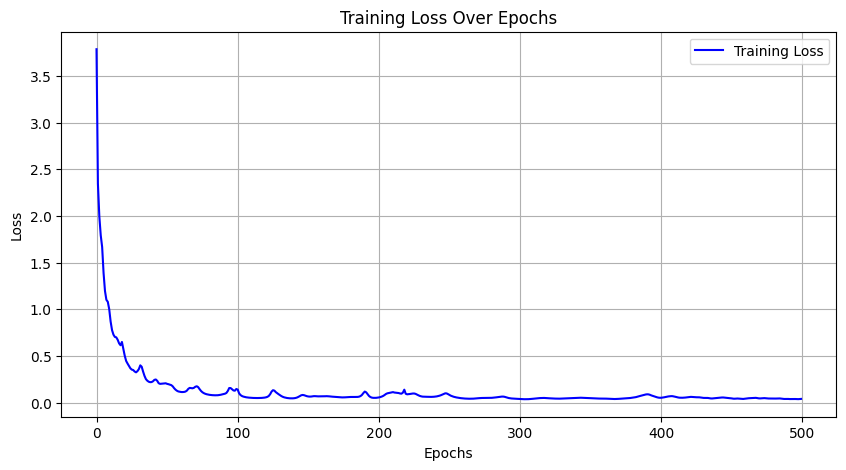


Confusion Matrix
[[40  4  4]
 [ 1 54  0]
 [ 3  3 59]]


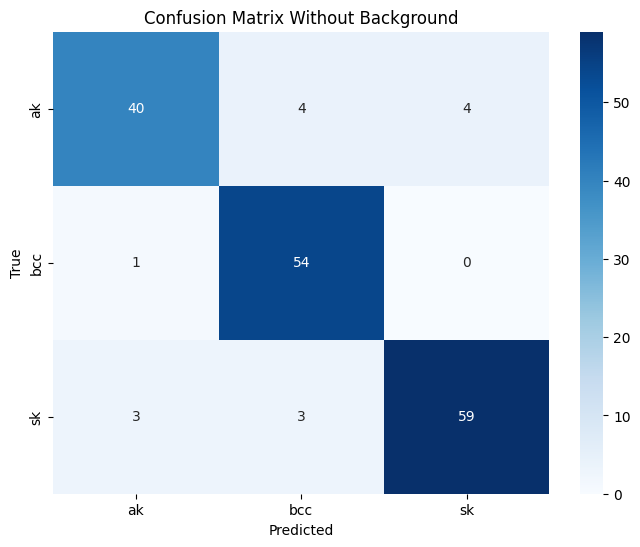

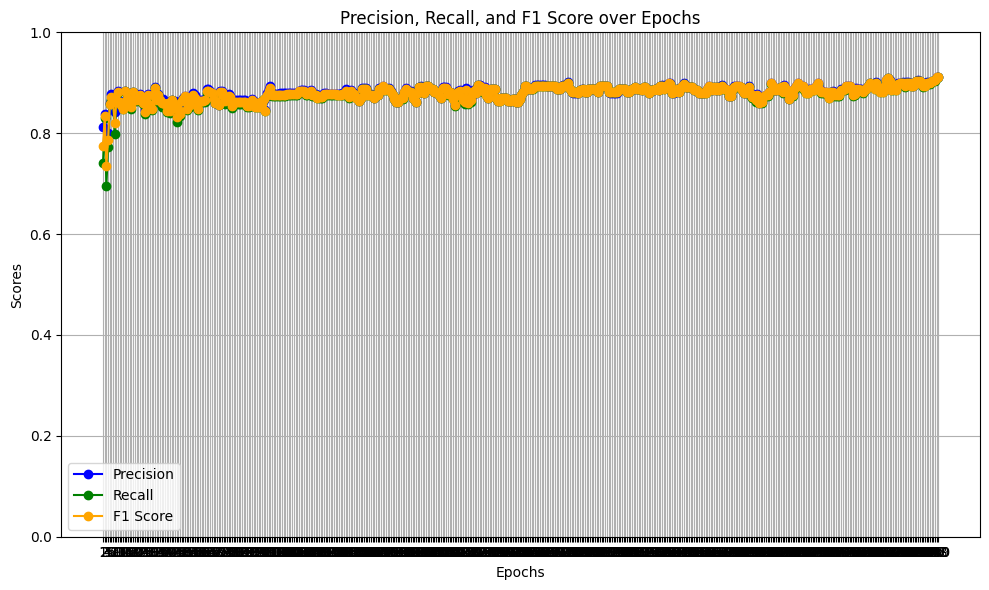

In [4]:
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor
from torchvision.datasets import CocoDetection
import torchvision.models.detection as detection
import torchvision.ops as ops
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_fscore_support,
                             average_precision_score,
                             classification_report,
                             confusion_matrix)
from sklearn.preprocessing import LabelBinarizer
import seaborn as sns
from pycocotools.coco import COCO
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


# Set random seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # Enable deterministic mode
    torch.backends.cudnn.benchmark = False  # Disable benchmark for consistent results

# Custom Transform Function
def custom_transform(image):
    return ToTensor()(image)

# Load class names from annotation file
def load_class_names(annotation_file):
    coco = COCO(annotation_file)
    return {id: coco.loadCats(id)[0]['name'] for id in coco.getCatIds()}

# Count the number of images in the dataset
def count_images(annotation_file):
    coco = COCO(annotation_file)
    return len(coco.imgs)

# Data Preparation
def create_dataloader(root, annotation_file, batch_size=32):
    dataset = CocoDetection(root=root, annFile=annotation_file, transforms=None)

    def collate_fn(batch):
        images, targets = zip(*batch)
        images = [custom_transform(img) for img in images]

        formatted_targets = []
        for target in targets:
            boxes = []
            labels = []
            for annotation in target:
                bbox = annotation['bbox']
                x_min, y_min, width, height = bbox
                x_max = x_min + width
                y_max = y_min + height
                boxes.append([x_min, y_min, x_max, y_max])
                labels.append(annotation['category_id'])

            formatted_targets.append({
                'boxes': torch.tensor(boxes, dtype=torch.float32),
                'labels': torch.tensor(labels, dtype=torch.int64)
            })

        return images, formatted_targets

    return DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# Load class names
class_names = load_class_names('/kaggle/working/SAVEaugmented-2/train/_annotations.coco.json')
print("Detected Classes:")
for id, name in class_names.items():
    print(f"ID: {id}, Name: {name}")

# Count images in train and validation datasets
num_train_images = count_images('/kaggle/working/SAVEaugmented-2/train/_annotations.coco.json')
num_valid_images = count_images('/kaggle/working/SAVEaugmented-2/valid/_annotations.coco.json')

print(f"Number of training images: {num_train_images}")
print(f"Number of validation images: {num_valid_images}")

train_loader = create_dataloader('/kaggle/working/SAVEaugmented-2/train', '/kaggle/working/SAVEaugmented-2/train/_annotations.coco.json', batch_size=32)
valid_loader = create_dataloader('/kaggle/working/SAVEaugmented-2/valid', '/kaggle/working/SAVEaugmented-2/valid/_annotations.coco.json', batch_size=32)

# Model Initialization
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = detection.ssd300_vgg16(pretrained=True)  # Use SSD with VGG300 backbone
model = model.to(device)

# IoU Calculation Function
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_box1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_box2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    iou = intersection / float(area_box1 + area_box2 - intersection + 1e-6)
    return iou

# Training
def train_one_epoch(model, data_loader, optimizer, device, epoch_losses):
    model.train()
    running_loss = 0.0
    for images, targets in data_loader:
        images = [img.to(device) for img in images]

        # Prepare targets
        formatted_targets = []
        for target in targets:
            boxes = target['boxes'].to(device)
            labels = target['labels'].to(device)
            formatted_targets.append({
                'boxes': boxes,
                'labels': labels
            })

        loss_dict = model(images, formatted_targets)
        losses = sum(loss for loss in loss_dict.values())
        running_loss += losses.item()

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

    epoch_loss = running_loss / len(data_loader)
    epoch_losses.append(epoch_loss)
    print(f'Average loss for this epoch: {epoch_loss}')
    predictions, targets, iou_values, scores = evaluate(model, valid_loader, device, confidence_threshold=0.5, iou_threshold=0.5)
    all_preds = predictions
    all_labels = targets

    if all_preds and all_labels:
        lb = LabelBinarizer()
        all_labels_bin = lb.fit_transform(all_labels)
        all_preds_bin = lb.transform(all_preds)

        precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
        pre.append(precision)
        rec.append(recall)
# Plot loss after training
def plot_losses(epoch_losses):
    plt.figure(figsize=(10, 5))
    plt.plot(epoch_losses, label="Training Loss", color='blue')
    plt.xlabel("Epochs")
    plt.ylabel("Loss")
    plt.title("Training Loss Over Epochs")
    plt.legend()
    plt.grid(True)
    plt.show()

def apply_nms(predictions, iou_threshold=0.5):
    boxes = predictions['boxes']
    scores = predictions['scores']
    keep = ops.nms(boxes, scores, iou_threshold)

    return {
        'boxes': boxes[keep],
        'labels': predictions['labels'][keep],
        'scores': scores[keep]
    }

def evaluate(model, data_loader, device, confidence_threshold=0.5, iou_threshold=0.5):
    model.eval()
    all_predictions = []
    all_targets = []
    iou_values = []
    all_scores = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            predictions = model(images)

            for pred, target in zip(predictions, targets):
                if len(pred['boxes']) == 0:
                    continue

                filtered_pred = apply_nms(pred, iou_threshold)

                boxes_pred = filtered_pred['boxes'].cpu().numpy()
                labels_pred = filtered_pred['labels'].cpu().numpy()
                scores_pred = filtered_pred['scores'].cpu().numpy()

                boxes_true = target['boxes'].cpu().numpy() if 'boxes' in target else np.array([])
                labels_true = target['labels'].cpu().numpy() if 'labels' in target else np.array([])

                for box_pred, label_pred, score_pred in zip(boxes_pred, labels_pred, scores_pred):
                    best_iou = 0
                    best_match_index = -1

                    for index, box_true in enumerate(boxes_true):
                        iou = calculate_iou(box_pred, box_true)
                        if iou > best_iou:
                            best_iou = iou
                            best_match_index = index

                    if best_iou >= iou_threshold and score_pred >= confidence_threshold:
                        all_predictions.append(label_pred)
                        all_targets.append(labels_true[best_match_index])
                        all_scores.append(score_pred)
                        iou_values.append(best_iou)

    return all_predictions, all_targets, iou_values, all_scores

def compute_metrics(predictions, targets, class_names):
    all_preds = predictions
    all_labels = targets

    if all_preds and all_labels:
        lb = LabelBinarizer()
        all_labels_bin = lb.fit_transform(all_labels)
        all_preds_bin = lb.transform(all_preds)

        precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
        ap = average_precision_score(all_labels_bin, all_preds_bin, average='weighted')

        print(f'Weighted Precision: {precision:.4f}')
        print(f'Weighted Recall: {recall:.4f}')
        print(f'Weighted F1 Score: {f1:.4f}')
        print(f'Average Precision: {ap:.4f}')

        unique_labels = np.unique(all_labels)
        target_names = [class_names[label] for label in unique_labels if label in class_names]
        report = classification_report(all_labels, all_preds, target_names=target_names, labels=unique_labels, output_dict=True)
        print("\nClass-wise metrics:")
        for class_name in class_names.values():
            if class_name in report:
                metrics = report[class_name]
                print(f"Class: {class_name}")
                print(f"  Precision: {metrics['precision']:.4f}")
                print(f"  Recall: {metrics['recall']:.4f}")
                print(f"  F1 Score: {metrics['f1-score']:.4f}\n")
            else:
                print(f"Class {class_name} not found in report.")
    else:
        print("No predictions or true labels to compute metrics.")

def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    print(cm)

    labels = [class_names[i] for i in range(1,len(class_names))]  # Adjust based on your actual class labels

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="g", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix Without Background")
    plt.show()

def precisionRecallF1ScoreCurve(pre, rec):
    # Convert inputs to numpy arrays
    precision = np.array(pre)
    recall = np.array(rec)

    # Calculate F1 scores
    f1_scores = 2 * (precision * recall) / (precision + recall)
    f1_scores = np.nan_to_num(f1_scores)  # Handle NaN values

    # Create an array for epochs
    epochs = np.arange(1, len(precision) + 1)

    # Plot all curves in a single plot
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, precision, marker='o', label='Precision', color='blue')
    plt.plot(epochs, recall, marker='o', label='Recall', color='green')
    plt.plot(epochs, f1_scores, marker='o', label='F1 Score', color='orange')

    # Adding labels and title
    plt.title('Precision, Recall, and F1 Score over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Scores')
    plt.xticks(epochs)  # Show each epoch on x-axis
    plt.ylim(0, 1)  # Y-axis from 0 to 1
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()


# Training and evaluation
optimizer = torch.optim.SGD(model.parameters(), lr=0.0005, momentum=0.9, weight_decay=0.0005)

# Create directory to save model
save_dir = '/kaggle/working/model'
os.makedirs(save_dir, exist_ok=True)

num_epochs = 500
epoch_losses = []
pre=[]
rec=[]
if num_train_images > 0:
    for epoch in range(num_epochs):
        print(f'Epoch {epoch + 1}/{num_epochs} running...')
        train_one_epoch(model, train_loader, optimizer, device, epoch_losses)
        print(f'Epoch {epoch + 1}/{num_epochs} completed')

        if (epoch + 1) % 10 == 0:
            model_path = os.path.join(save_dir, f'model_epoch_{epoch + 1}.pth')
            torch.save(model.state_dict(), model_path)
            print(f'Model saved at {model_path}')

    # Evaluate and compute metrics with thresholds on the validation set
    predictions, targets, iou_values, scores = evaluate(model, valid_loader, device, confidence_threshold=0.5, iou_threshold=0.5)
    compute_metrics(predictions, targets, class_names)

    # Plot losses
    plot_losses(epoch_losses)
    print("\nConfusion Matrix")

    # Plot confusion matrix
    plot_confusion_matrix(targets, predictions, class_names)
    print("\n\n")
    precisionRecallF1ScoreCurve(pre, rec)

else:
    print("No training images found. Please check your dataset.")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def precisionRecallF1ScoreCurve(pre, rec):
    # Convert inputs to numpy arrays
    precision = np.array(pre)
    recall = np.array(rec)

    # Calculate F1 scores
    f1_scores = 2 * (precision * recall) / (precision + recall)
    f1_scores = np.nan_to_num(f1_scores)  # Handle NaN values

    # Create an array for epochs
    epochs = np.arange(1, len(precision) + 1)

    # Plot all curves in a single plot
    plt.figure(figsize=(10, 6))

    plt.plot(epochs, precision, marker='o', label='Precision', color='blue')
    plt.plot(epochs, recall, marker='o', label='Recall', color='green')
    plt.plot(epochs, f1_scores, marker='o', label='F1 Score', color='orange')

    # Adding labels and title
    plt.title('Precision, Recall, and F1 Score over Epochs')
    plt.xlabel('Epochs')
    plt.ylabel('Scores')

    # Set x-ticks to display every 25 epochs
    plt.xticks(np.arange(0, len(precision) + 1, 25))  # Show ticks at 25, 50, ..., up to max epochs
    plt.ylim(0, 1)  # Y-axis from 0 to 1
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()


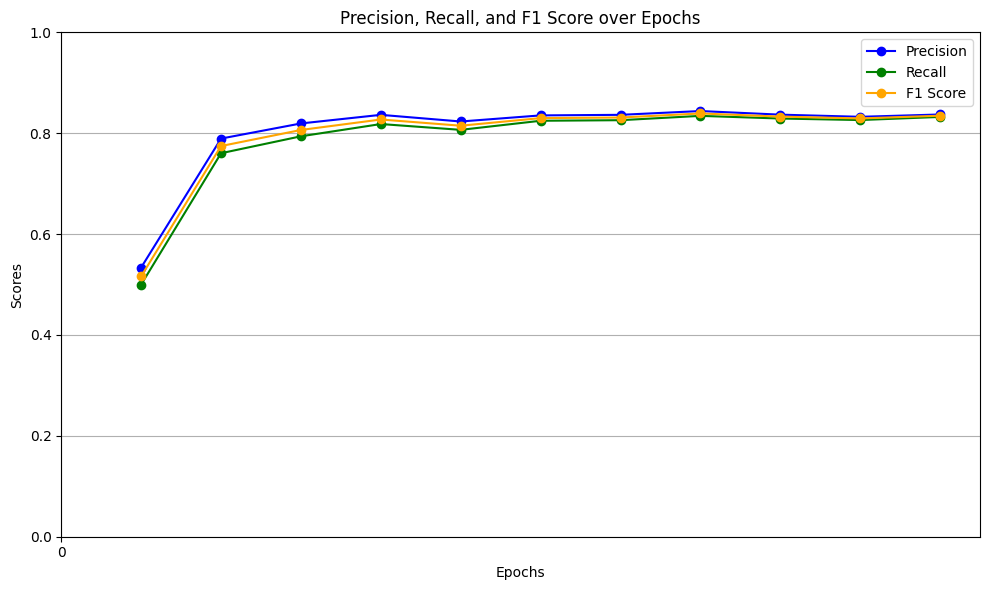

In [ ]:
precisionRecallF1ScoreCurve(pre, rec)

/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/conda/lib/python3.10/site-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)
Downloading: "https://download.pytorch.org/models/vgg16_features-amdegroot-88682ab5.pth" to /root/.cache/torch/hub/checkpoints/vgg16_features-amdegroot-88682ab5.pth
100%|██████████| 528M/528M [00:02<00:00, 228MB/s]  
/tmp/ipykernel_30/3828141010.py:26: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during u

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Detected Classes:
ID: 0, Name: trf78wey89
ID: 1, Name: ak
ID: 2, Name: bcc
ID: 3, Name: sk
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Number of testing images: 88
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Weighted Precision: 0.9663
Weighted Recall: 0.9630
Weighted F1 Score: 0.9632
Average Precision: 0.9407

Class-wise metrics:
Class trf78wey89 not found in report.
Class: ak
  Precision: 1.0000
  Recall: 0.9167
  F1 Score: 0.9565

Class: bcc
  Precision: 1.0000
  Recall: 0.9630
  F1 Score: 0.9811

Class: sk
  Precision: 0.9091
  Recall: 1.0000
  F1 Score: 0.9524

Class-wise Accuracy:
Accuracy for AK: 0.92
Accuracy for BCC: 0.96
Accuracy for SK: 1.00
[[22  0  2]
 [ 0 26  1]
 [ 0  0 30]]


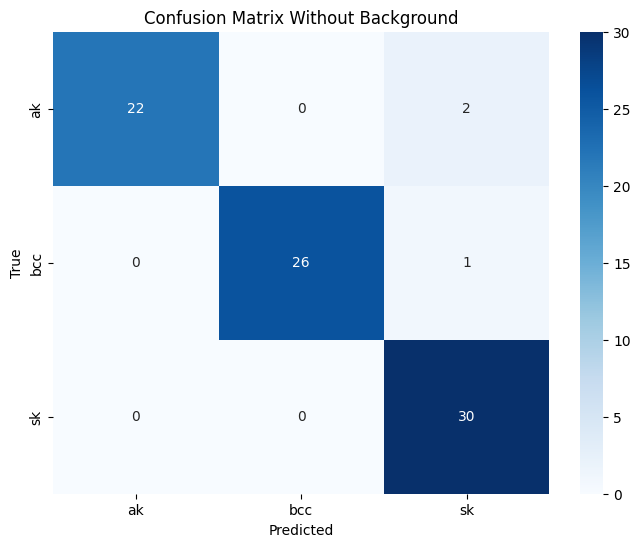

In [3]:
import torch
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader
from torchvision.transforms import ToTensor
from torchvision.datasets import CocoDetection
from torchvision.models import detection
import torchvision.ops as ops
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_fscore_support,
                             average_precision_score,
                             classification_report,
                             confusion_matrix)
from sklearn.preprocessing import LabelBinarizer
import seaborn as sns
from pycocotools.coco import COCO
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the model
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = detection.ssd300_vgg16(pretrained=False)
state_dict = torch.load('/kaggle/working//model/model_epoch_20.pth', map_location=device)

# Attempt to load the state dictionary
try:
    model.load_state_dict(state_dict, strict=False)
except RuntimeError as e:
    print(f"Error loading state dict: {e}")

model.eval()
model.to(device)


# Set random seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # Enable deterministic mode
    torch.backends.cudnn.benchmark = False  # Disable benchmark for consistent results

# Custom Transform Function
def custom_transform(image):
    return ToTensor()(image)

# Load class names from annotation file
def load_class_names(annotation_file):
    coco = COCO(annotation_file)
    return {id: coco.loadCats(id)[0]['name'] for id in coco.getCatIds()}

# Count the number of images in the dataset
def count_images(annotation_file):
    coco = COCO(annotation_file)
    return len(coco.imgs)

# Data Preparation
def create_dataloader(root, annotation_file, batch_size=32):
    dataset = CocoDetection(root=root, annFile=annotation_file, transforms=None)

    def collate_fn(batch):
        images, targets = zip(*batch)
        images = [custom_transform(img) for img in images]

        formatted_targets = []
        for target in targets:
            boxes = []
            labels = []
            for annotation in target:
                bbox = annotation['bbox']
                x_min, y_min, width, height = bbox
                x_max = x_min + width
                y_max = y_min + height
                boxes.append([x_min, y_min, x_max, y_max])
                labels.append(annotation['category_id'])

            formatted_targets.append({
                'boxes': torch.tensor(boxes, dtype=torch.float32),
                'labels': torch.tensor(labels, dtype=torch.int64)
            })

        return images, formatted_targets

    return DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# Load class names
class_names = load_class_names('/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json')
print("Detected Classes:")
for id, name in class_names.items():
    print(f"ID: {id}, Name: {name}")

# Count images in train and validation datasets
num_test_images = count_images('/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json')


print(f"Number of testing images: {num_test_images}")


test_loader = create_dataloader('/kaggle/working/SAVEaugmented-2/test/', '/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json', batch_size=32)



# IoU Calculation Function
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_box1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_box2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    iou = intersection / float(area_box1 + area_box2 - intersection + 1e-6)
    return iou


def apply_nms(predictions, iou_threshold=0.5):
    boxes = predictions['boxes']
    scores = predictions['scores']
    keep = ops.nms(boxes, scores, iou_threshold)

    return {
        'boxes': boxes[keep],
        'labels': predictions['labels'][keep],
        'scores': scores[keep]
    }

def evaluate(model, data_loader, device, confidence_threshold=0.6, iou_threshold=0.5):
    model.eval()
    all_predictions = []
    all_targets = []
    iou_values = []
    all_scores = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            predictions = model(images)

            for pred, target in zip(predictions, targets):
                if len(pred['boxes']) == 0:
                    continue

                filtered_pred = apply_nms(pred, iou_threshold)

                boxes_pred = filtered_pred['boxes'].cpu().numpy()
                labels_pred = filtered_pred['labels'].cpu().numpy()
                scores_pred = filtered_pred['scores'].cpu().numpy()

                boxes_true = target['boxes'].cpu().numpy() if 'boxes' in target else np.array([])
                labels_true = target['labels'].cpu().numpy() if 'labels' in target else np.array([])

                for box_pred, label_pred, score_pred in zip(boxes_pred, labels_pred, scores_pred):
                    best_iou = 0
                    best_match_index = -1

                    for index, box_true in enumerate(boxes_true):
                        iou = calculate_iou(box_pred, box_true)
                        if iou > best_iou:
                            best_iou = iou
                            best_match_index = index

                    if best_iou >= iou_threshold and score_pred >= confidence_threshold:
                        all_predictions.append(label_pred)
                        all_targets.append(labels_true[best_match_index])
                        all_scores.append(score_pred)
                        iou_values.append(best_iou)

    return all_predictions, all_targets, iou_values, all_scores

def compute_metrics(predictions, targets, class_names):
    all_preds = predictions
    all_labels = targets

    if all_preds and all_labels:
        lb = LabelBinarizer()
        all_labels_bin = lb.fit_transform(all_labels)
        all_preds_bin = lb.transform(all_preds)

        precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
        ap = average_precision_score(all_labels_bin, all_preds_bin, average='weighted')

        print(f'Weighted Precision: {precision:.4f}')
        print(f'Weighted Recall: {recall:.4f}')
        print(f'Weighted F1 Score: {f1:.4f}')
        print(f'Average Precision: {ap:.4f}')

        unique_labels = np.unique(all_labels)
        target_names = [class_names[label] for label in unique_labels if label in class_names]
        report = classification_report(all_labels, all_preds, target_names=target_names, labels=unique_labels, output_dict=True)
        print("\nClass-wise metrics:")
        for class_name in class_names.values():
            if class_name in report:
                metrics = report[class_name]
                print(f"Class: {class_name}")
                print(f"  Precision: {metrics['precision']:.4f}")
                print(f"  Recall: {metrics['recall']:.4f}")
                print(f"  F1 Score: {metrics['f1-score']:.4f}\n")
            else:
                print(f"Class {class_name} not found in report.")
    else:
        print("No predictions or true labels to compute metrics.")

def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    import numpy as np


    # Given confusion matrix
    confusion_mat = np.array(cm)

    # Calculate true positives, false positives, etc.
    TP = np.diag(confusion_mat)
    FP = confusion_mat.sum(axis=0) - TP
    FN = confusion_mat.sum(axis=1) - TP
    TN = confusion_mat.sum() - (FP + FN + TP)

    # Calculate accuracy for each class
    accuracy = TP / (TP + FN)
    print("Class-wise Accuracy:")
    print(f"Accuracy for AK: {accuracy[0]:.2f}")
    print(f"Accuracy for BCC: {accuracy[1]:.2f}")
    print(f"Accuracy for SK: {accuracy[2]:.2f}")



    print(cm)

    labels = [class_names[i] for i in range(1,len(class_names))]  # Adjust based on your actual class labels

    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="g", cmap="Blues", xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.title("Confusion Matrix Without Background")
    plt.show()





# Evaluate and compute metrics with thresholds on the validation set
predictions, targets, iou_values, scores = evaluate(model, test_loader, device, confidence_threshold=0.6, iou_threshold=0.5)
compute_metrics(predictions, targets, class_names)

# Plot confusion matrix
plot_confusion_matrix(targets, predictions, class_names)



In [5]:

# Load the model


# Attempt to load the state dictionary



# Set random seed for reproducibility
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True  # Enable deterministic mode
    torch.backends.cudnn.benchmark = False  # Disable benchmark for consistent results

# Custom Transform Function
def custom_transform(image):
    return ToTensor()(image)

# Load class names from annotation file
def load_class_names(annotation_file):
    coco = COCO(annotation_file)
    return {id: coco.loadCats(id)[0]['name'] for id in coco.getCatIds()}

# Count the number of images in the dataset
def count_images(annotation_file):
    coco = COCO(annotation_file)
    return len(coco.imgs)

# Data Preparation
def create_dataloader(root, annotation_file, batch_size=32):
    dataset = CocoDetection(root=root, annFile=annotation_file, transforms=None)

    def collate_fn(batch):
        images, targets = zip(*batch)
        images = [custom_transform(img) for img in images]

        formatted_targets = []
        for target in targets:
            boxes = []
            labels = []
            for annotation in target:
                bbox = annotation['bbox']
                x_min, y_min, width, height = bbox
                x_max = x_min + width
                y_max = y_min + height
                boxes.append([x_min, y_min, x_max, y_max])
                labels.append(annotation['category_id'])

            formatted_targets.append({
                'boxes': torch.tensor(boxes, dtype=torch.float32),
                'labels': torch.tensor(labels, dtype=torch.int64)
            })

        return images, formatted_targets

    return DataLoader(dataset, batch_size=batch_size, shuffle=False, collate_fn=collate_fn)

# Load class names
class_names = load_class_names('/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json')
print("Detected Classes:")
for id, name in class_names.items():
    print(f"ID: {id}, Name: {name}")

# Count images in train and validation datasets
num_test_images = count_images('/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json')


print(f"Number of testing images: {num_test_images}")


test_loader = create_dataloader('/kaggle/working/SAVEaugmented-2/test', '/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json', batch_size=32)



# IoU Calculation Function
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_box1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_box2 = (box2[2] - box2[0]) * (box2[3] - box2[1])

    iou = intersection / float(area_box1 + area_box2 - intersection + 1e-6)
    return iou


def apply_nms(predictions, iou_threshold=0.5):
    boxes = predictions['boxes']
    scores = predictions['scores']
    keep = ops.nms(boxes, scores, iou_threshold)

    return {
        'boxes': boxes[keep],
        'labels': predictions['labels'][keep],
        'scores': scores[keep]
    }

def evaluate(model, data_loader, device, confidence_threshold=0.5, iou_threshold=0.5):
    model.eval()
    all_predictions = []
    all_targets = []
    iou_values = []
    all_scores = []

    with torch.no_grad():
        for images, targets in data_loader:
            images = [img.to(device) for img in images]
            predictions = model(images)

            for pred, target in zip(predictions, targets):
                if len(pred['boxes']) == 0:
                    continue

                filtered_pred = apply_nms(pred, iou_threshold)

                boxes_pred = filtered_pred['boxes'].cpu().numpy()
                labels_pred = filtered_pred['labels'].cpu().numpy()
                scores_pred = filtered_pred['scores'].cpu().numpy()

                boxes_true = target['boxes'].cpu().numpy() if 'boxes' in target else np.array([])
                labels_true = target['labels'].cpu().numpy() if 'labels' in target else np.array([])

                for box_pred, label_pred, score_pred in zip(boxes_pred, labels_pred, scores_pred):
                    best_iou = 0
                    best_match_index = -1

                    for index, box_true in enumerate(boxes_true):
                        iou = calculate_iou(box_pred, box_true)
                        if iou > best_iou:
                            best_iou = iou
                            best_match_index = index

                    if best_iou >= iou_threshold and score_pred >= confidence_threshold:
                        all_predictions.append(label_pred)
                        all_targets.append(labels_true[best_match_index])
                        all_scores.append(score_pred)
                        iou_values.append(best_iou)

    return all_predictions, all_targets, iou_values, all_scores

def compute_metrics(predictions, targets, class_names):
    all_preds = predictions
    all_labels = targets

    if all_preds and all_labels:
        lb = LabelBinarizer()
        all_labels_bin = lb.fit_transform(all_labels)
        all_preds_bin = lb.transform(all_preds)

        precision, recall, f1, _ = precision_recall_fscore_support(all_labels, all_preds, average='weighted')
        ap = average_precision_score(all_labels_bin, all_preds_bin, average='weighted')

        return (precision+recall+f1+ap)/4


def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    import numpy as np
    # Given confusion matrix
    confusion_mat = np.array(cm)
    return np.sum(confusion_mat)

import os

# Specify the folder path
folder_path = '/kaggle/working/model'

# Get the list of all files in the specified folder
file_names = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f))]
ans=[]
count=1
for i in file_names:
    print(f'{count}/50')
    device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
    model = detection.ssd300_vgg16(pretrained=False)
    state_dict = torch.load(f'/kaggle/working/model/{i}', map_location=device)
    try:
        model.load_state_dict(state_dict, strict=False)
    except RuntimeError as e:
        print(f"Error loading state dict: {e}")

    model.eval()
    model.to(device)
    # Evaluate and compute metrics with thresholds on the validation set
    predictions, targets, iou_values, scores = evaluate(model, test_loader, device, confidence_threshold=0.6, iou_threshold=0.5)
    ans.append([plot_confusion_matrix(targets, predictions, class_names), compute_metrics(predictions, targets, class_names),i])
    count+=1

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Detected Classes:
ID: 0, Name: trf78wey89
ID: 1, Name: ak
ID: 2, Name: bcc
ID: 3, Name: sk
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Number of testing images: 88
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
1/50


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
Downloading: "https://download.pytorch.org/models/vgg16_features-amdegroot-88682ab5.pth" to /root/.cache/torch/hub/checkpoints/vgg16_features-amdegroot-88682ab5.pth
100%|██████████| 528M/528M [00:16<00:00, 33.5MB/s] 
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Ar

2/50


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

3/50


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

... (90 outputs left out)

49/50


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

50/50


The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` fo

In [6]:

# Sort the list by first value (descending), and then by second value (also descending)
sorted_data = sorted(ans, key=lambda x: (x[0], x[1]), reverse=True)

# Print the sorted list
for item in sorted_data:
    print(item)


[81, 0.9583021506780103, 'model_epoch_20.pth']
[81, 0.9219863318644079, 'model_epoch_40.pth']
[81, 0.9161545315636562, 'model_epoch_490.pth']
[80, 0.9359095348133436, 'model_epoch_60.pth']
[80, 0.9296447978246893, 'model_epoch_280.pth']
[80, 0.9289543009347446, 'model_epoch_130.pth']
[80, 0.9289543009347446, 'model_epoch_150.pth']
[80, 0.9289373222682781, 'model_epoch_110.pth']
[80, 0.9153721899653567, 'model_epoch_120.pth']
[80, 0.9153721899653567, 'model_epoch_140.pth']
[80, 0.9151429228261161, 'model_epoch_480.pth']
[80, 0.9151429228261161, 'model_epoch_500.pth']
[80, 0.9146033846712638, 'model_epoch_50.pth']
[80, 0.901522240634103, 'model_epoch_360.pth']
[80, 0.9015055443548388, 'model_epoch_440.pth']
[80, 0.9015055443548388, 'model_epoch_460.pth']
[80, 0.9015055443548388, 'model_epoch_470.pth']
[80, 0.9014925235215053, 'model_epoch_430.pth']
[80, 0.9014925235215053, 'model_epoch_170.pth']
[79, 0.9562284568971531, 'model_epoch_390.pth']
[79, 0.9424879019116472, 'model_epoch_100.pth

The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.

Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.

You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` 

loading annotations into memory...

Done (t=0.00s)

creating index...

index created!

loading annotations into memory...

Done (t=0.00s)

creating index...

index created!


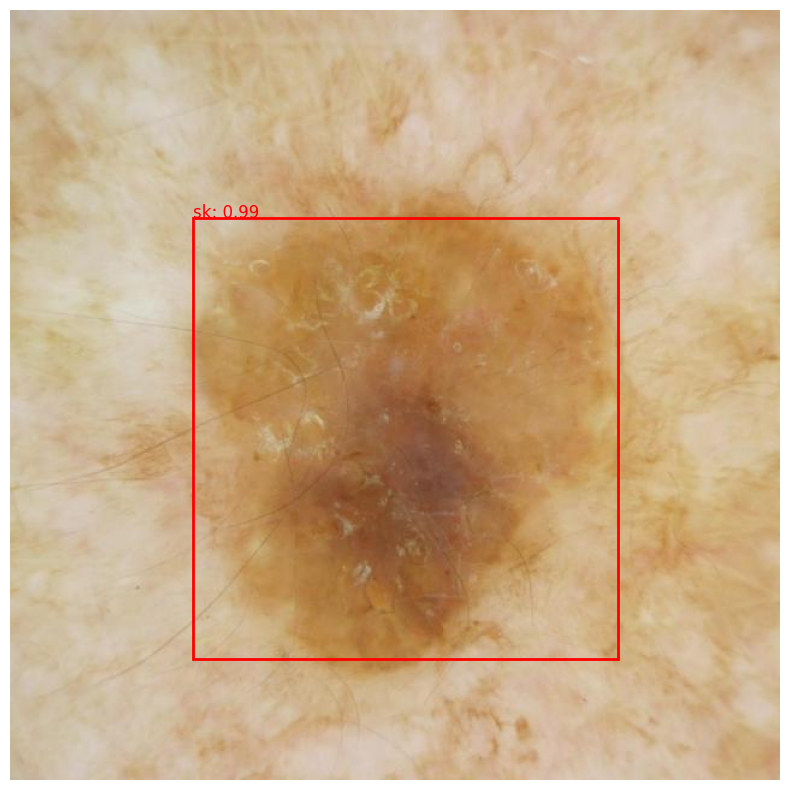

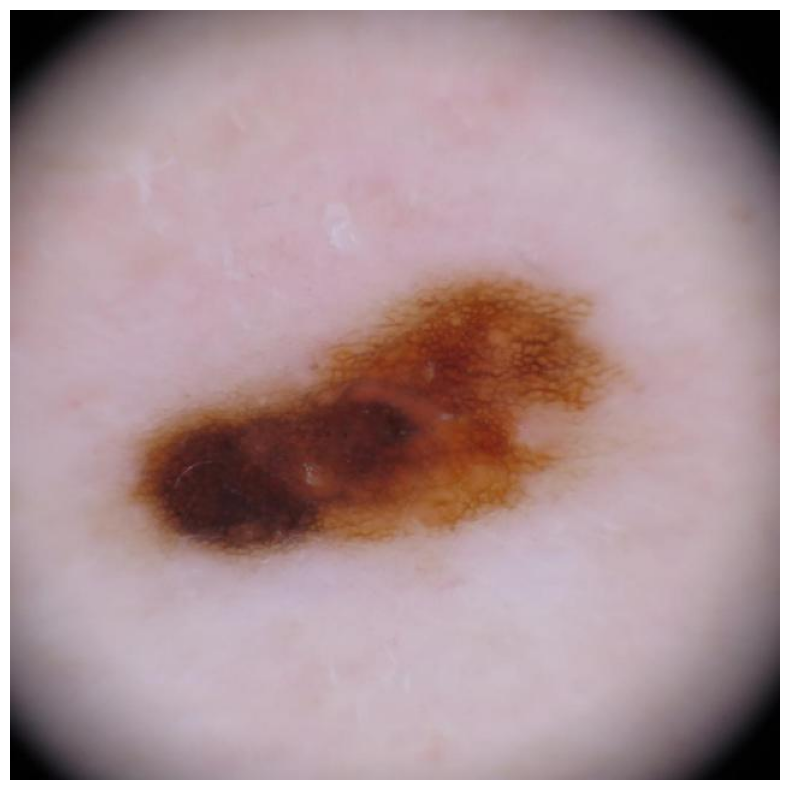

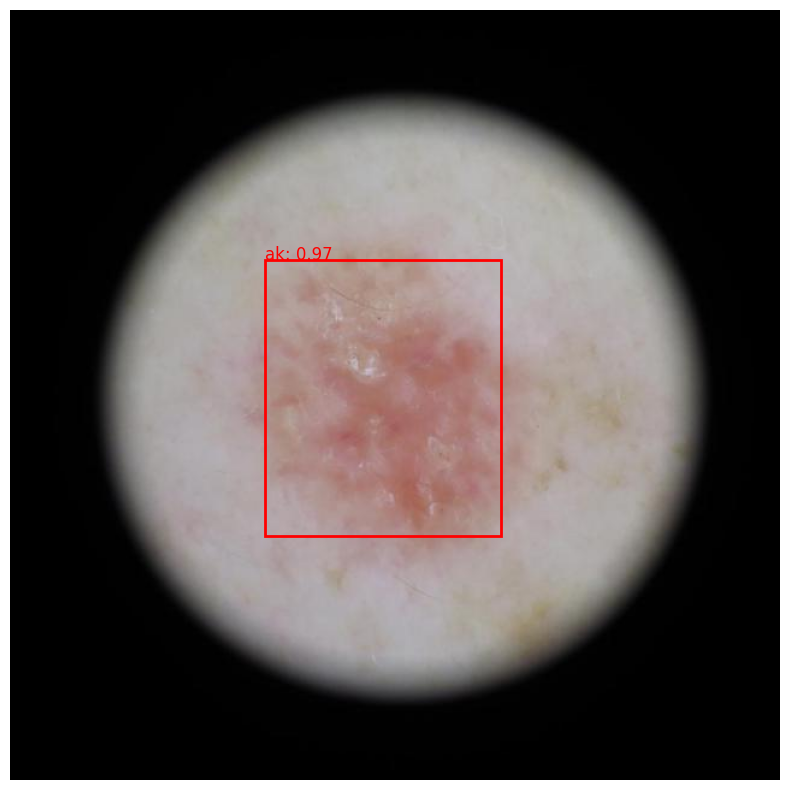

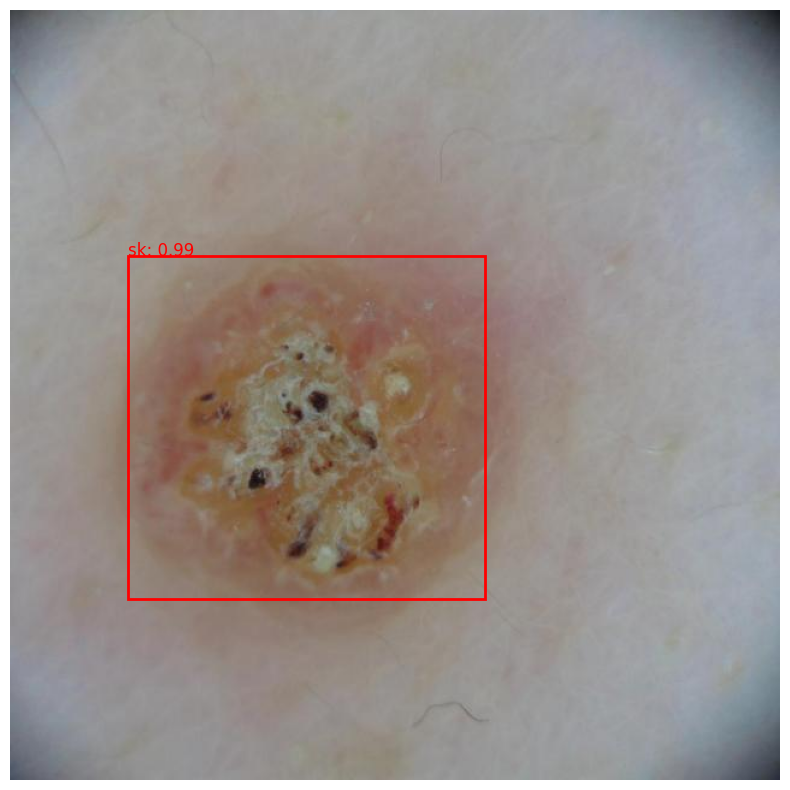

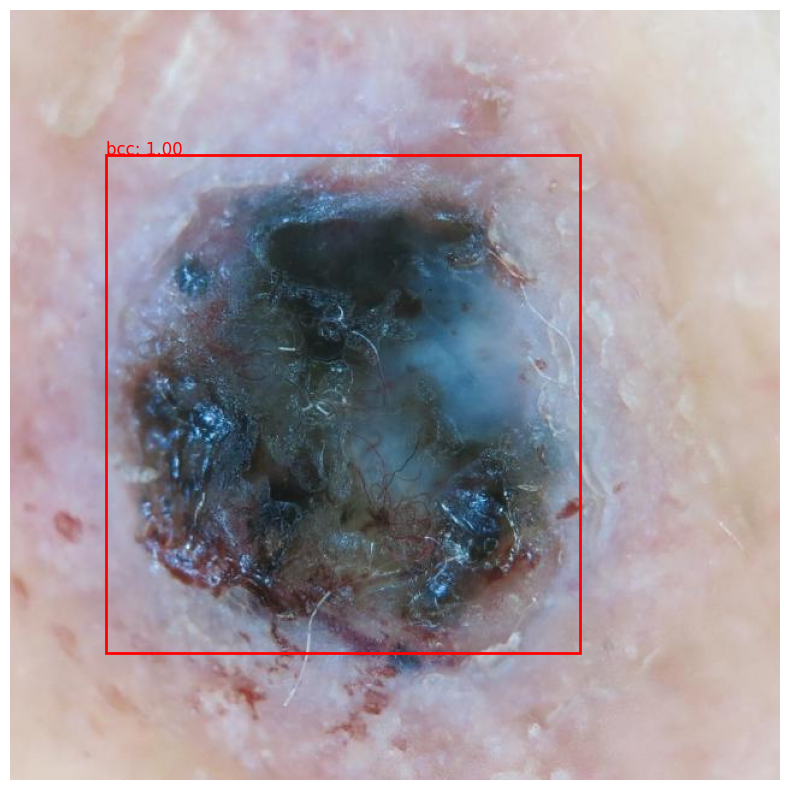

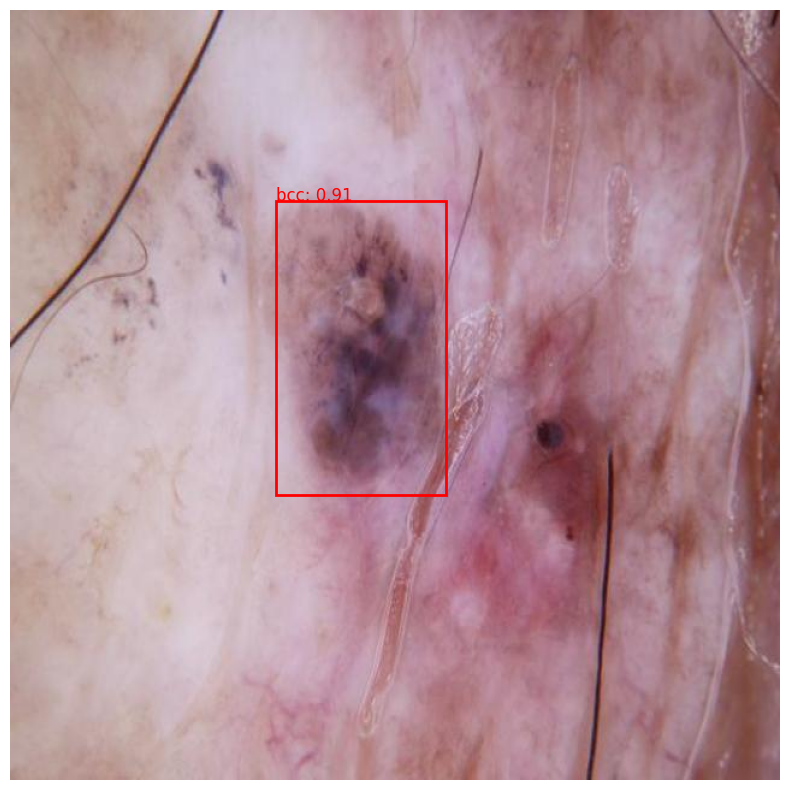

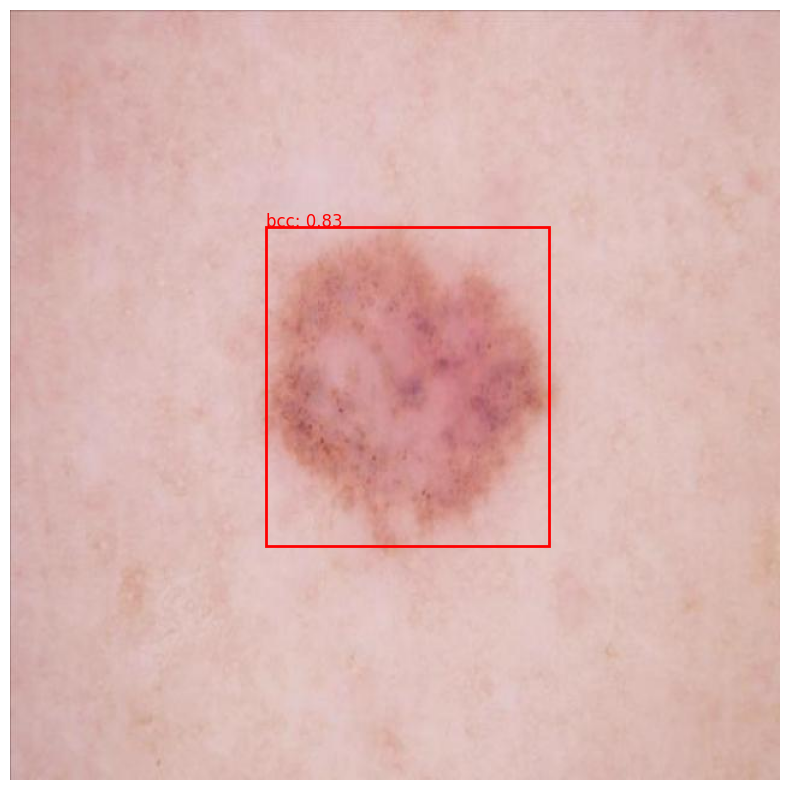

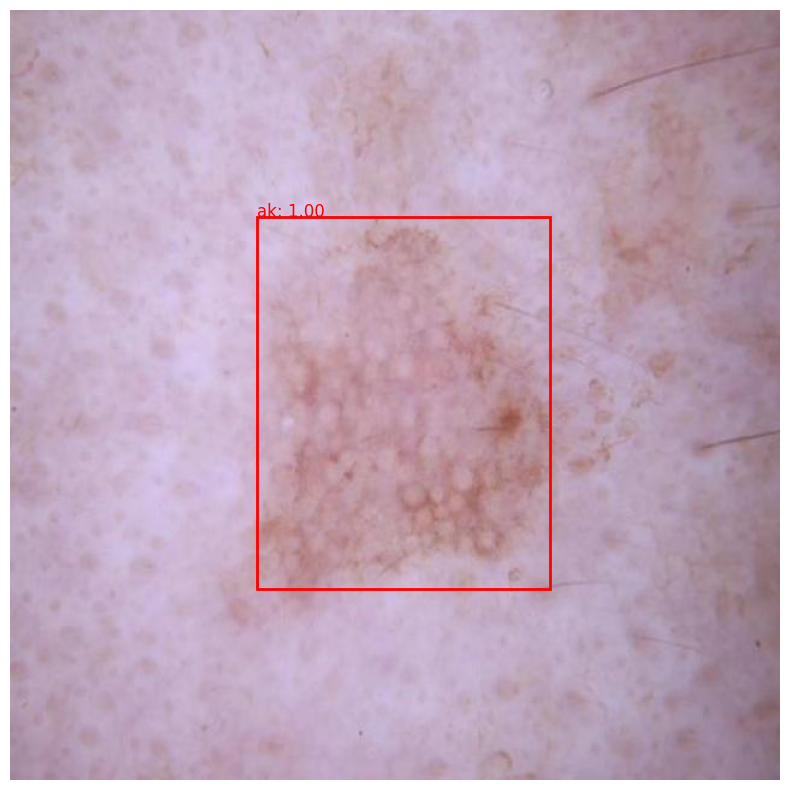

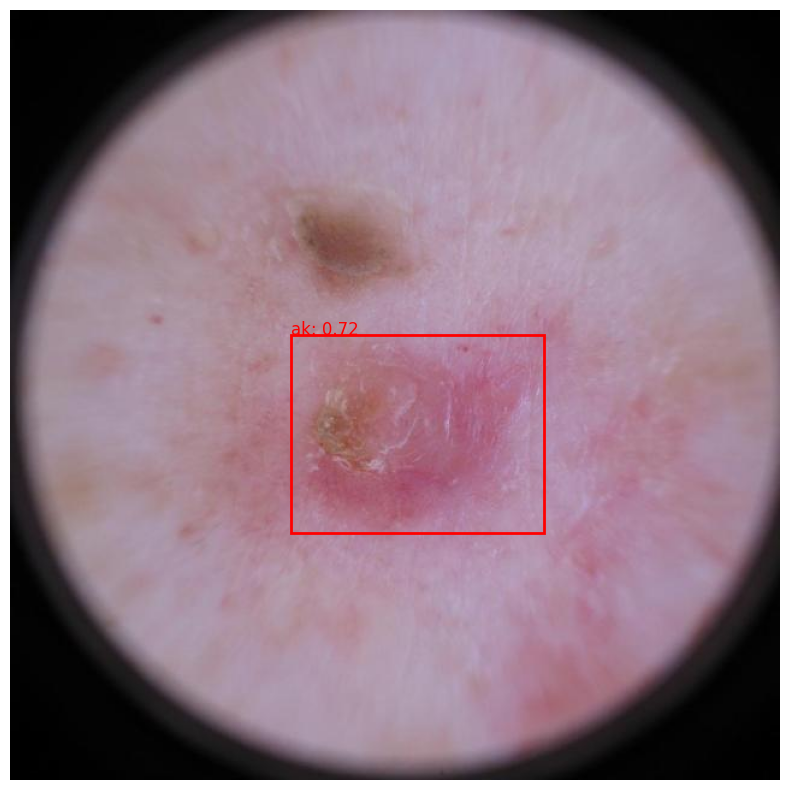

In [ ]:
import os
import torch
from torchvision.models import detection
from torchvision.transforms import ToTensor
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Load the model
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model = detection.ssd300_vgg16(pretrained=False)
state_dict = torch.load('/content/model/model_epoch_10.pth', map_location=device)

# Attempt to load the state dictionary
try:
    model.load_state_dict(state_dict, strict=False)
except RuntimeError as e:
    print(f"Error loading state dict: {e}")

model.eval()
model.to(device)

# Load class names
def load_class_names(annotation_file):
    from pycocotools.coco import COCO
    coco = COCO(annotation_file)
    return {id: coco.loadCats(id)[0]['name'] for id in coco.getCatIds()}

class_names = load_class_names('/kaggle/working/SAVEaugmented-2/valid/_annotations.coco.json')

# IoU Calculation
def calculate_iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    intersection = max(0, x2 - x1) * max(0, y2 - y1)
    area_box1 = (box1[2] - box1[0]) * (box1[3] - box1[1])
    area_box2 = (box2[2] - box2[0]) * (box2[3] - box2[1])
    union = area_box1 + area_box2 - intersection

    return intersection / union if union > 0 else 0

# Function to load ground truth boxes (modify this based on your dataset)
def load_ground_truth_boxes(annotation_file):
    from pycocotools.coco import COCO
    coco = COCO(annotation_file)
    ground_truth_boxes = []
    image_ids = coco.getImgIds()
    for img_id in image_ids:
        ann_ids = coco.getAnnIds(imgIds=img_id)
        annotations = coco.loadAnns(ann_ids)
        for ann in annotations:
            bbox = ann['bbox']  # [x, y, width, height]
            x_min = bbox[0]
            y_min = bbox[1]
            x_max = bbox[0] + bbox[2]
            y_max = bbox[1] + bbox[3]
            ground_truth_boxes.append((x_min, y_min, x_max, y_max))
    return ground_truth_boxes

# Load images from a specific directory
def load_images_from_directory(directory):
    images = []
    for filename in os.listdir(directory):
        if filename.endswith(('.png', '.jpg', '.jpeg')):
            img_path = os.path.join(directory, filename)
            img = Image.open(img_path).convert("RGB")
            images.append(img)
    return images

# Inference function with IoU threshold
def inference(model, images, device, ground_truth_boxes, confidence_threshold=0.5, iou_threshold=0.5):
    model.eval()
    all_predictions = []

    with torch.no_grad():
        for img in images:
            img_tensor = ToTensor()(img).unsqueeze(0).to(device)
            predictions = model(img_tensor)

            boxes = predictions[0]['boxes'].cpu().numpy()
            scores = predictions[0]['scores'].cpu().numpy()
            labels = predictions[0]['labels'].cpu().numpy()

            high_conf_idx = np.where(scores >= confidence_threshold)[0]
            boxes = boxes[high_conf_idx]
            labels = labels[high_conf_idx]
            scores = scores[high_conf_idx]

            # Filter predictions based on IoU with ground truth boxes
            filtered_boxes = []
            filtered_labels = []
            filtered_scores = []

            for i, box in enumerate(boxes):
                if any(calculate_iou(box, gt_box) > iou_threshold for gt_box in ground_truth_boxes):
                    filtered_boxes.append(box)
                    filtered_labels.append(labels[i])
                    filtered_scores.append(scores[i])

            all_predictions.append((np.array(filtered_boxes), np.array(filtered_labels), np.array(filtered_scores)))

    return all_predictions
# Function to visualize predictions
def plot_predictions(images, predictions, class_names):
    for img, (boxes, labels, scores) in zip(images, predictions):
        plt.figure(figsize=(10, 10))
        plt.imshow(img)
        ax = plt.gca()

        for box, label, score in zip(boxes, labels, scores):
            x_min, y_min, x_max, y_max = box

            # Check if label exists in class_names
            label_name = class_names.get(label, "Unknown")

            ax.add_patch(plt.Rectangle((x_min, y_min), x_max - x_min, y_max - y_min,
                                        fill=False, color='red', linewidth=2))
            ax.text(x_min, y_min, f'{label_name}: {score:.2f}', color='red', fontsize=12)

        plt.axis('off')
        plt.show()


# Specify the directory containing test images
test_images_directory = '/kaggle/working/SAVEaugmented-2/test/'  # Update this path
images = load_images_from_directory(test_images_directory)

# Load ground truth boxes
ground_truth_boxes = load_ground_truth_boxes('/kaggle/working/SAVEaugmented-2/test/_annotations.coco.json')

# Run inference on the loaded images
predictions = inference(model, images, device, ground_truth_boxes, confidence_threshold=0.6, iou_threshold=0.5)


# Visualize the predictions
plot_predictions(images, predictions, class_names)


In [4]:
import shutil

# Specify the folder you want to zip
folder_to_zip = '/kaggle/working/model'  # Change this to your folder path
zip_file_name = '/kaggle/working/WLI.zip'  # Change this to your desired zip file path

# Create a zip file
shutil.make_archive(zip_file_name.replace('.zip', ''), 'zip', folder_to_zip)

print(f"Zipped {folder_to_zip} to {zip_file_name}")


Zipped /kaggle/working/model to /kaggle/working/WLI.zip


In [ ]:
import os
import shutil

# Define source and destination directories
source_dir = '/kaggle/working/model'
destination_dir = '/kaggle/working/weights'
excluded_file = 'WLIWeights.zip'

# Create the destination directory if it doesn't exist
os.makedirs(destination_dir, exist_ok=True)

# Iterate through files in the source directory
for filename in os.listdir(source_dir):
    if filename != excluded_file:
        # Construct full file path
        src_file = os.path.join(source_dir, filename)
        dst_file = os.path.join(destination_dir, filename)

        # Move the file
        shutil.move(src_file, dst_file)

print("Files moved successfully, except for:", excluded_file)


Files moved successfully, except for: WLIWeights.zip
